In [1]:
import time
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
cols = ["SD_front", "SD_left", "SD_right", "SD_back", "Class"]
df = pd.read_csv("../wall+following+robot+navigation+data/sensor_readings_4.data", header=None, names=cols)

X = df[cols[:-1]].to_numpy()
classes, y = np.unique(df["Class"], return_inverse=True)

ORDENS = {"1/2": 1/2, "2/3": 2/3, "1": 1, "3/2": 3/2, "2": 2, "5/2": 5/2}
SPLITS = {"20/80": 0.2, "30/70": 0.3, "50/50": 0.5, "70/30": 0.7, "80/20": 0.8}
RODADAS = 100
STATS = ["mean", "std", "max", "min", "median"]

In [3]:
def treinar(X, y):
    return X, y  # 1-NN apenas memoriza o conjunto de treino


def prever(modelo, X, m):
    Xtr, ytr = modelo
    # raiz de ordem 1/m omitida: é monotônica, não altera o argmin
    d = sum(np.abs(X[:, [k]] - Xtr[:, k]) ** m for k in range(X.shape[1]))
    return ytr[d.argmin(axis=1)]


def matriz_confusao(y_true, y_pred, k):
    return np.bincount(y_true * k + y_pred, minlength=k * k).reshape(k, k)

In [4]:
rng = np.random.default_rng(42)
registros, confusoes = [], {}

for split, frac in SPLITS.items():
    n_tr = int(frac * len(y))
    for r in range(RODADAS):
        idx = rng.permutation(len(y))
        tr, te = idx[:n_tr], idx[n_tr:]
        for nome, m in ORDENS.items():
            t0 = time.perf_counter()
            modelo = treinar(X[tr], y[tr])
            t1 = time.perf_counter()
            pred = prever(modelo, X[te], m)
            t2 = time.perf_counter()

            cm = matriz_confusao(y[te], pred, len(classes))
            confusoes[split, nome, r] = cm
            registros.append({
                "split": split, "m": nome, "rodada": r,
                "acuracia": cm.trace() / cm.sum(),
                "t_treino": t1 - t0, "t_teste": t2 - t1,
                **dict(zip(classes, cm.diagonal() / cm.sum(axis=1))),
            })

res = pd.DataFrame(registros)

In [5]:
grupos = res.groupby(["split", "m"], sort=False)
tabela = grupos["acuracia"].agg(STATS).join(grupos[["t_treino", "t_teste"]].mean())
display(tabela.round(4))

mean     std     max     min  median  t_treino  t_teste
split m                                                             
20/80 1/2  0.9468  0.0041  0.9592  0.9361  0.9468    0.0001   0.2690
      2/3  0.9468  0.0044  0.9583  0.9352  0.9464    0.0001   0.5898
      1    0.9469  0.0046  0.9585  0.9345  0.9473    0.0001   0.2975
      3/2  0.9458  0.0046  0.9576  0.9340  0.9460    0.0001   0.5731
      2    0.9440  0.0048  0.9528  0.9294  0.9444    0.0001   0.2656
      5/2  0.9432  0.0049  0.9533  0.9276  0.9433    0.0001   0.5764
30/70 1/2  0.9562  0.0040  0.9657  0.9414  0.9563    0.0001   0.3805
      2/3  0.9564  0.0039  0.9641  0.9401  0.9569    0.0001   0.8228
      1    0.9567  0.0038  0.9644  0.9424  0.9569    0.0001   0.4142
      3/2  0.9560  0.0039  0.9641  0.9408  0.9563    0.0001   0.8149
      2    0.9548  0.0039  0.9631  0.9411  0.9551    0.0001   0.3779
      5/2  0.9540  0.0039  0.9620  0.9406  0.9542    0.0001   0.8296
50/50 1/2  0.9651  0.0038  0.9718  0.9545  0.9657    0.0001   0.4498
      2/3  0.9653  0.0036  0.9725  0.9538  0.9659    0.0001   0.9322
      1    0.9652  0.0033  0.9721  0.9527  0.9655    0.0001   0.4880
      3/2  0.9653  0.0033  0.9732  0.9520  0.9655    0.0001   0.9390
      2    0.9644  0.0036  0.9714  0.9498  0.9641    0.0001   0.4412
      5/2  0.9638  0.0034  0.9707  0.9490  0.9635    0.0001   0.9358
70/30 1/2  0.9700  0.0039  0.9774  0.9609  0.9701    0.0001   0.3488
      2/3  0.9698  0.0037  0.9792  0.9609  0.9698    0.0001   0.7821
      1    0.9703  0.0038  0.9786  0.9627  0.9701    0.0001   0.3882
      3/2  0.9705  0.0037  0.9817  0.9627  0.9701    0.0001   0.7823
      2    0.9700  0.0036  0.9805  0.9621  0.9701    0.0001   0.3482
      5/2  0.9693  0.0037  0.9805  0.9615  0.9682    0.0001   0.7726
80/20 1/2  0.9715  0.0050  0.9835  0.9560  0.9716    0.0001   0.2651
      2/3  0.9723  0.0045  0.9835  0.9579  0.9716    0.0001   0.5889
      1    0.9723  0.0044  0.9817  0.9579  0.9725    0.0001   0.2919
      3/2  0.9724  0.0044  0.9835  0.9588  0.9725    0.0001   0.5986
      2    0.9718  0.0045  0.9826  0.9588  0.9716    0.0001   0.2563
      5/2  0.9717  0.0045  0.9844  0.9597  0.9716    0.0001   0.5827

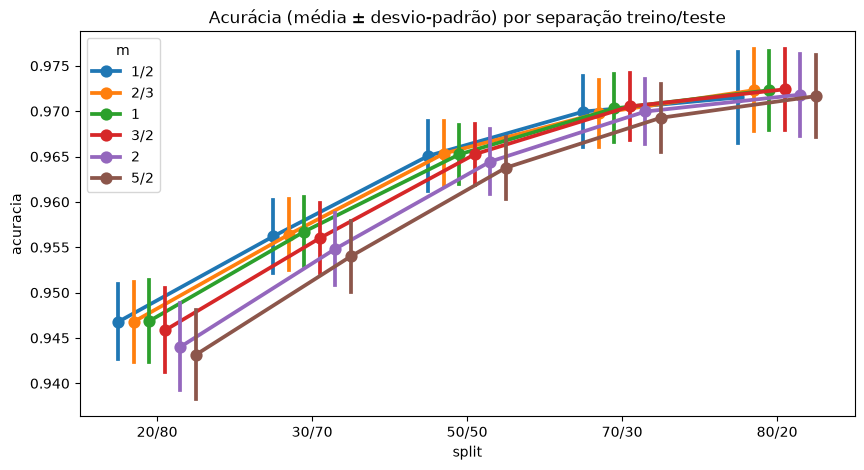

In [6]:
plt.figure(figsize=(10, 5))
sns.pointplot(res, x="split", y="acuracia", hue="m", errorbar="sd", dodge=0.5)
plt.title("Acurácia (média ± desvio-padrão) por separação treino/teste");

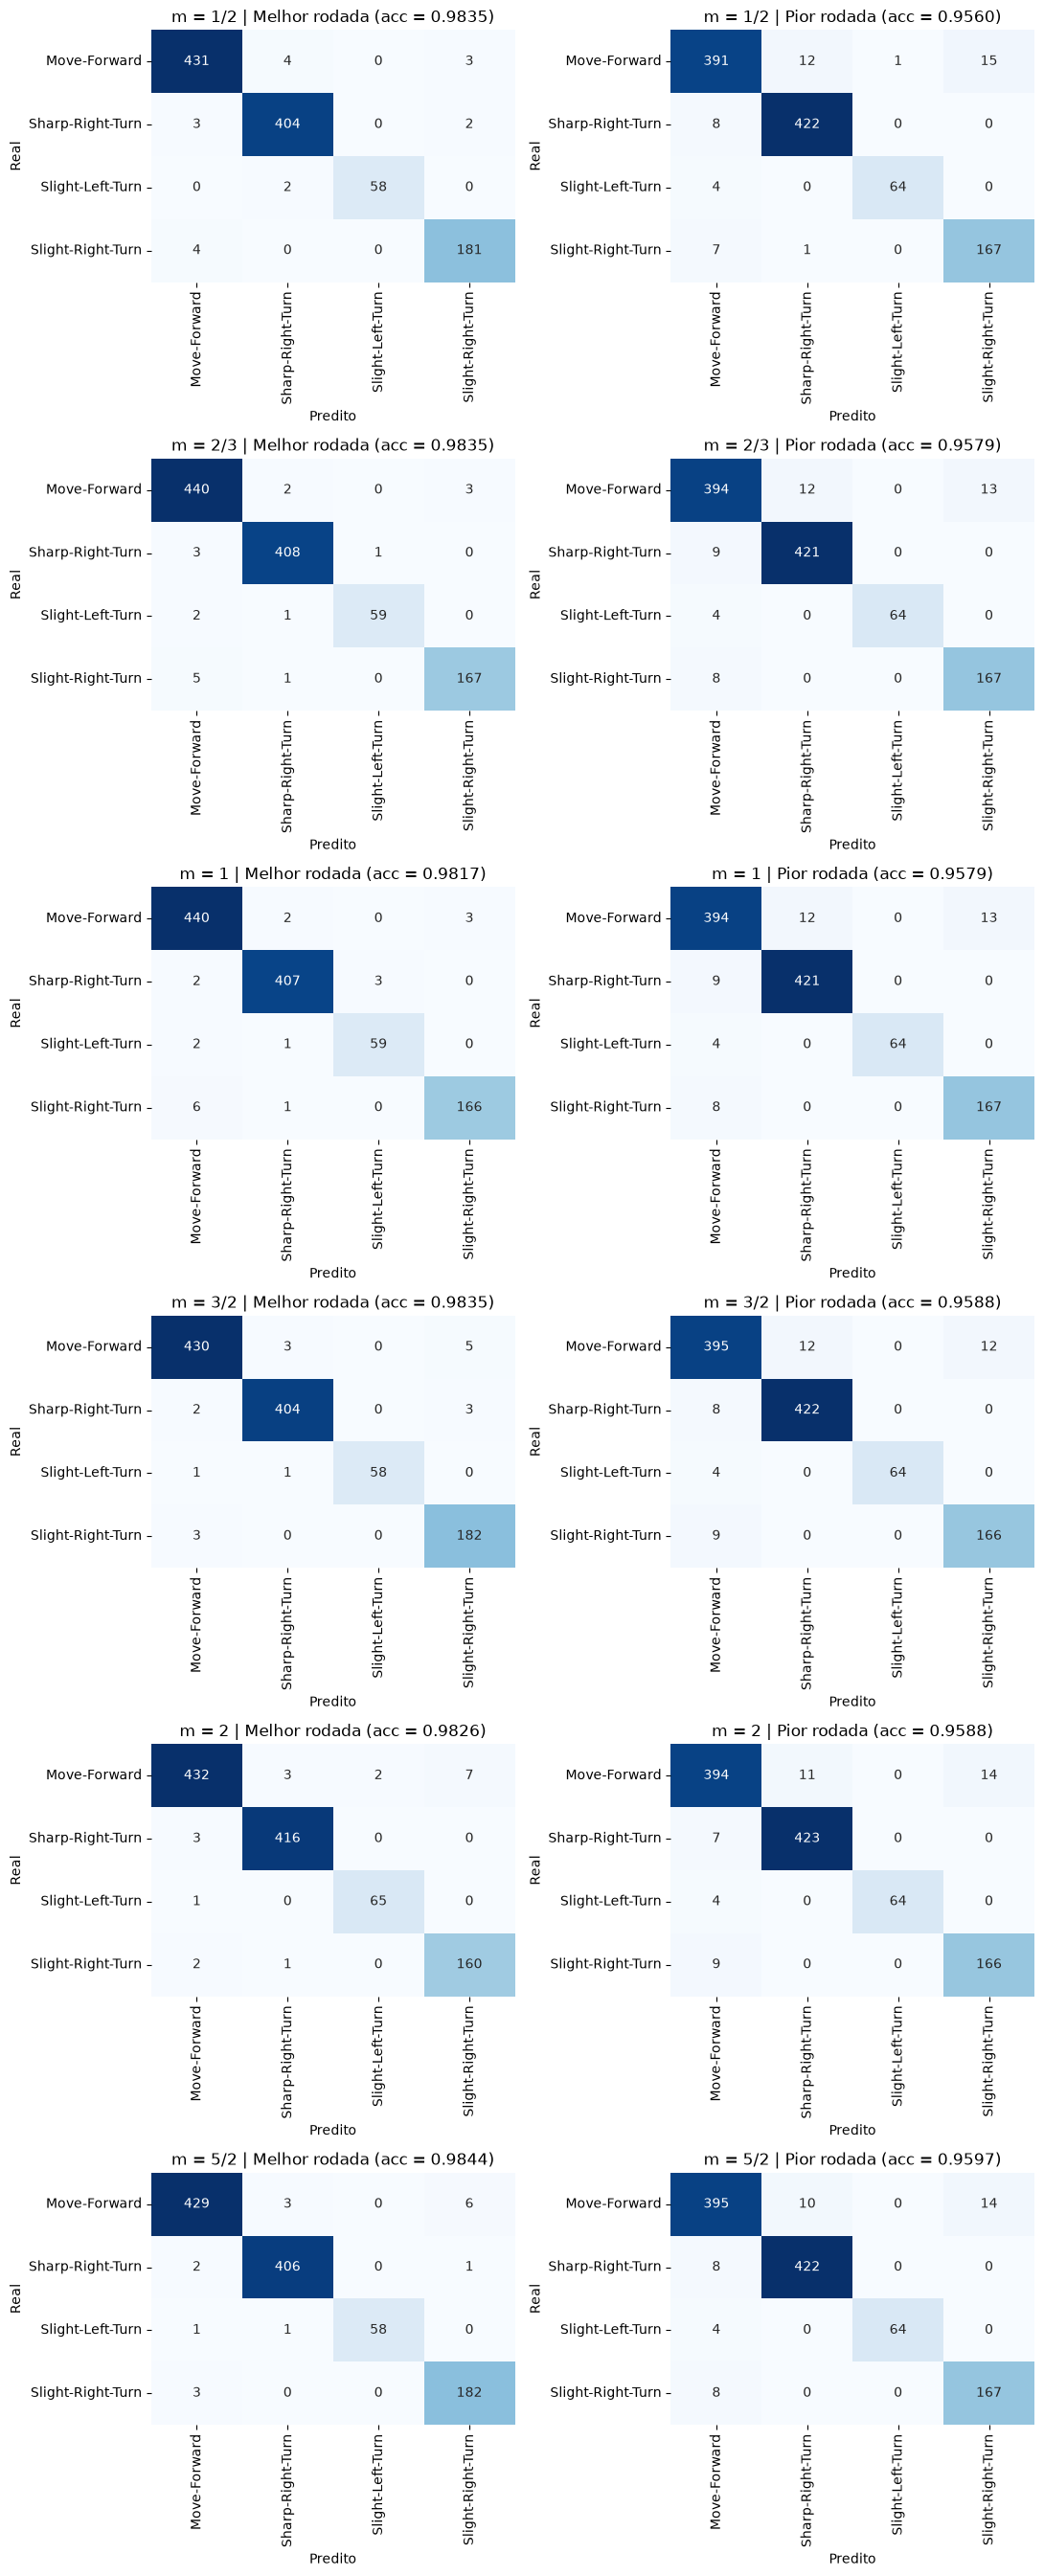

In [7]:
SPLIT_REF = "80/20"
ref = res[res["split"] == SPLIT_REF]

fig, axes = plt.subplots(len(ORDENS), 2, figsize=(11, 4.5 * len(ORDENS)))
for linha, nome in zip(axes, ORDENS):
    sub = ref[ref["m"] == nome]
    for ax, (rotulo, i) in zip(linha, [("Melhor", sub["acuracia"].idxmax()), ("Pior", sub["acuracia"].idxmin())]):
        cm = confusoes[SPLIT_REF, nome, sub.loc[i, "rodada"]]
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                    xticklabels=classes, yticklabels=classes, ax=ax)
        ax.set(title=f"m = {nome} | {rotulo} rodada (acc = {sub.loc[i, 'acuracia']:.4f})",
               xlabel="Predito", ylabel="Real")
plt.tight_layout()

In [8]:
por_classe = res.melt(id_vars=["split", "m"], value_vars=list(classes),
                      var_name="classe", value_name="acuracia_classe")

for classe, g in por_classe.groupby("classe"):
    print(classe)
    display(g.groupby(["split", "m"], sort=False)["acuracia_classe"].agg(STATS).round(4))

Move-Forward


mean     std     max     min  median
split m                                          
20/80 1/2  0.9384  0.0095  0.9590  0.9067  0.9391
      2/3  0.9393  0.0096  0.9583  0.9061  0.9400
      1    0.9406  0.0098  0.9617  0.9118  0.9408
      3/2  0.9410  0.0100  0.9611  0.9122  0.9417
      2    0.9398  0.0097  0.9606  0.9111  0.9397
      5/2  0.9393  0.0097  0.9583  0.9111  0.9397
30/70 1/2  0.9499  0.0078  0.9669  0.9337  0.9487
      2/3  0.9508  0.0075  0.9669  0.9338  0.9501
      1    0.9517  0.0078  0.9688  0.9349  0.9518
      3/2  0.9513  0.0078  0.9682  0.9338  0.9509
      2    0.9502  0.0080  0.9676  0.9316  0.9496
      5/2  0.9493  0.0081  0.9670  0.9296  0.9483
50/50 1/2  0.9596  0.0065  0.9741  0.9427  0.9595
      2/3  0.9616  0.0062  0.9792  0.9468  0.9613
      1    0.9622  0.0058  0.9748  0.9453  0.9627
      3/2  0.9620  0.0060  0.9761  0.9471  0.9625
      2    0.9609  0.0061  0.9752  0.9467  0.9608
      5/2  0.9597  0.0059  0.9737  0.9453  0.9598
70/30 1/2  0.9654  0.0071  0.9801  0.9484  0.9658
      2/3  0.9674  0.0064  0.9810  0.9510  0.9668
      1    0.9686  0.0061  0.9811  0.9555  0.9691
      3/2  0.9683  0.0064  0.9835  0.9493  0.9682
      2    0.9672  0.0065  0.9835  0.9525  0.9678
      5/2  0.9659  0.0066  0.9835  0.9493  0.9668
80/20 1/2  0.9667  0.0090  0.9864  0.9332  0.9674
      2/3  0.9706  0.0083  0.9888  0.9403  0.9715
      1    0.9712  0.0083  0.9911  0.9403  0.9724
      3/2  0.9704  0.0085  0.9888  0.9427  0.9717
      2    0.9692  0.0085  0.9888  0.9403  0.9697
      5/2  0.9682  0.0084  0.9888  0.9427  0.9692

Sharp-Right-Turn


mean     std     max     min  median
split m                                          
20/80 1/2  0.9675  0.0064  0.9813  0.9486  0.9673
      2/3  0.9682  0.0064  0.9831  0.9480  0.9686
      1    0.9687  0.0069  0.9822  0.9521  0.9689
      3/2  0.9670  0.0072  0.9825  0.9482  0.9675
      2    0.9657  0.0076  0.9827  0.9459  0.9662
      5/2  0.9647  0.0079  0.9821  0.9393  0.9655
30/70 1/2  0.9728  0.0061  0.9896  0.9523  0.9729
      2/3  0.9736  0.0062  0.9889  0.9517  0.9737
      1    0.9749  0.0057  0.9876  0.9578  0.9742
      3/2  0.9743  0.0058  0.9869  0.9537  0.9735
      2    0.9739  0.0058  0.9862  0.9571  0.9731
      5/2  0.9733  0.0059  0.9857  0.9564  0.9725
50/50 1/2  0.9789  0.0054  0.9906  0.9628  0.9794
      2/3  0.9790  0.0054  0.9906  0.9619  0.9795
      1    0.9793  0.0054  0.9915  0.9674  0.9794
      3/2  0.9793  0.0052  0.9897  0.9681  0.9796
      2    0.9791  0.0051  0.9896  0.9663  0.9791
      5/2  0.9790  0.0051  0.9902  0.9658  0.9793
70/30 1/2  0.9810  0.0052  0.9903  0.9693  0.9806
      2/3  0.9800  0.0053  0.9934  0.9704  0.9800
      1    0.9807  0.0051  0.9934  0.9693  0.9803
      3/2  0.9804  0.0047  0.9918  0.9693  0.9812
      2    0.9805  0.0045  0.9918  0.9702  0.9809
      5/2  0.9807  0.0047  0.9918  0.9693  0.9812
80/20 1/2  0.9833  0.0067  0.9954  0.9667  0.9835
      2/3  0.9822  0.0063  0.9954  0.9667  0.9828
      1    0.9826  0.0059  0.9950  0.9670  0.9831
      3/2  0.9827  0.0062  0.9975  0.9698  0.9819
      2    0.9826  0.0063  0.9975  0.9697  0.9831
      5/2  0.9835  0.0061  0.9975  0.9707  0.9837

Slight-Left-Turn


mean     std     max     min  median
split m                                          
20/80 1/2  0.9279  0.0197  0.9621  0.8841  0.9302
      2/3  0.9306  0.0194  0.9699  0.8913  0.9335
      1    0.9282  0.0199  0.9699  0.8889  0.9316
      3/2  0.9263  0.0206  0.9693  0.8780  0.9290
      2    0.9249  0.0199  0.9693  0.8780  0.9265
      5/2  0.9248  0.0201  0.9693  0.8780  0.9259
30/70 1/2  0.9391  0.0170  0.9697  0.8844  0.9397
      2/3  0.9402  0.0171  0.9780  0.8800  0.9408
      1    0.9387  0.0177  0.9780  0.8844  0.9395
      3/2  0.9377  0.0186  0.9736  0.8756  0.9396
      2    0.9364  0.0182  0.9700  0.8800  0.9383
      5/2  0.9363  0.0180  0.9700  0.8800  0.9363
50/50 1/2  0.9465  0.0180  0.9870  0.9012  0.9471
      2/3  0.9463  0.0174  0.9817  0.8970  0.9475
      1    0.9434  0.0179  0.9817  0.8848  0.9455
      3/2  0.9431  0.0180  0.9769  0.8848  0.9462
      2    0.9417  0.0183  0.9740  0.8848  0.9446
      5/2  0.9412  0.0185  0.9756  0.8854  0.9441
70/30 1/2  0.9506  0.0224  0.9902  0.8972  0.9522
      2/3  0.9511  0.0219  0.9897  0.8990  0.9526
      1    0.9490  0.0221  0.9903  0.8879  0.9502
      3/2  0.9495  0.0223  1.0000  0.8879  0.9505
      2    0.9475  0.0232  1.0000  0.8879  0.9500
      5/2  0.9457  0.0229  0.9903  0.8879  0.9479
80/20 1/2  0.9533  0.0258  1.0000  0.8788  0.9568
      2/3  0.9538  0.0250  1.0000  0.8788  0.9586
      1    0.9509  0.0251  0.9872  0.8788  0.9524
      3/2  0.9508  0.0262  1.0000  0.8788  0.9549
      2    0.9497  0.0268  1.0000  0.8750  0.9535
      5/2  0.9484  0.0261  0.9872  0.8750  0.9516

Slight-Right-Turn


mean     std     max     min  median
split m                                          
20/80 1/2  0.9243  0.0153  0.9599  0.8786  0.9247
      2/3  0.9191  0.0162  0.9575  0.8651  0.9173
      1    0.9158  0.0172  0.9507  0.8636  0.9142
      3/2  0.9131  0.0171  0.9492  0.8621  0.9104
      2    0.9080  0.0180  0.9507  0.8576  0.9077
      5/2  0.9061  0.0183  0.9492  0.8561  0.9061
30/70 1/2  0.9380  0.0151  0.9696  0.8790  0.9397
      2/3  0.9344  0.0153  0.9696  0.8807  0.9352
      1    0.9313  0.0157  0.9667  0.8688  0.9319
      3/2  0.9296  0.0167  0.9707  0.8535  0.9307
      2    0.9262  0.0176  0.9649  0.8501  0.9273
      5/2  0.9248  0.0178  0.9667  0.8484  0.9255
50/50 1/2  0.9521  0.0122  0.9787  0.9052  0.9507
      2/3  0.9485  0.0127  0.9736  0.9028  0.9475
      1    0.9466  0.0128  0.9760  0.9100  0.9454
      3/2  0.9473  0.0130  0.9760  0.9116  0.9460
      2    0.9460  0.0132  0.9760  0.9047  0.9463
      5/2  0.9451  0.0135  0.9760  0.9000  0.9439
70/30 1/2  0.9619  0.0116  0.9874  0.9228  0.9616
      2/3  0.9579  0.0126  0.9800  0.9043  0.9592
      1    0.9572  0.0141  0.9921  0.9000  0.9586
      3/2  0.9600  0.0135  0.9921  0.9043  0.9616
      2    0.9596  0.0140  0.9921  0.9043  0.9615
      5/2  0.9588  0.0143  0.9921  0.9000  0.9614
80/20 1/2  0.9618  0.0148  1.0000  0.9153  0.9630
      2/3  0.9591  0.0146  0.9935  0.9156  0.9612
      1    0.9580  0.0149  0.9935  0.9156  0.9597
      3/2  0.9603  0.0148  0.9935  0.9221  0.9630
      2    0.9604  0.0144  0.9871  0.9235  0.9628
      5/2  0.9601  0.0143  0.9871  0.9235  0.9626

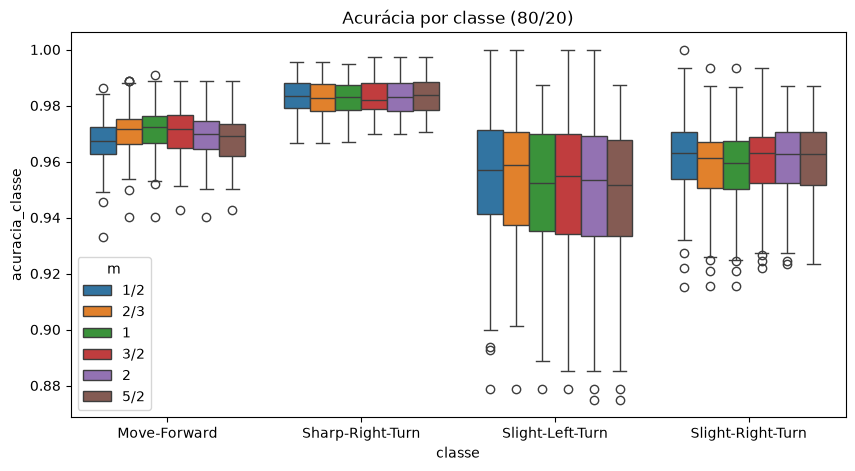

In [9]:
plt.figure(figsize=(10, 5))
sns.boxplot(por_classe[por_classe["split"] == SPLIT_REF], x="classe", y="acuracia_classe", hue="m")
plt.title(f"Acurácia por classe ({SPLIT_REF})");